<a href="https://colab.research.google.com/github/KRSets07/python-course-project/blob/main/Week_6_Assignment%7C_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stope Stability Clustering Analysis

This notebook applies unsupervised machine learning to identify natural groupings within a stope stability dataset. Unlike supervised learning, clustering does not use a target variable. Instead, it groups observations based on similarities in their geotechnical and geometric characteristics.

The objective is to investigate whether distinct groups of stopes exist based on their stability-related parameters.

In [69]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [70]:
df = pd.read_excel(
    "STOPE ID.xlsx",
    sheet_name="Stope Data"
)

df.head()

,Stope Name,Surface,Q',A,B,C,Top Length (m),Bottom Length (m),North Height (m),South Height (m),N',HR,ELOS (m)
0,TAU_115_STO_S_22,HW,2.0,1,0.4,4.3,34.420,34.090,32.601,30.540,3.4,8.1,1.736231
1,TAU_115_STO_S_22,FW,2.0,1,0.4,4.0,34.332,34.079,30.966,29.811,3.2,8.0,0.215763
2,NKW_115_STO_N_29,HW,2.0,1,0.3,4.7,30.080,30.126,31.609,32.008,2.8,7.8,1.466264
3,NKW_115_STO_N_29,FW,2.0,1,0.3,5.2,30.090,30.017,32.031,31.173,3.1,7.6,0.225319
4,TAU_115_STO_S_17,HW,2.0,1,0.3,3.9,34.024,34.258,36.381,32.733,2.3,8.4,1.329881


In [71]:
features = [
    "Q'",
    "N'",
    "HR",
    "ELOS (m)"
]

X = df[features].dropna()

X.head()

,Q',N',HR,ELOS (m)
0,2.0,3.4,8.1,1.736231
1,2.0,3.2,8.0,0.215763
2,2.0,2.8,7.8,1.466264
3,2.0,3.1,7.6,0.225319
4,2.0,2.3,8.4,1.329881


In [72]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [73]:
inertia = []

K = range(1,11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

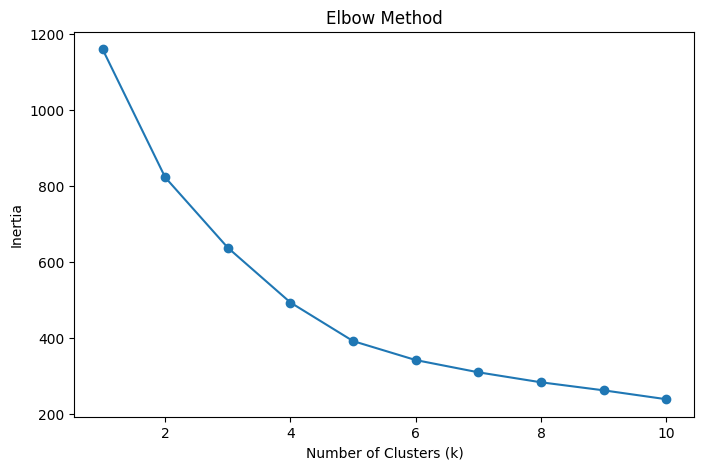

In [74]:
plt.figure(figsize=(8,5))

plt.plot(K, inertia, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [75]:
scores = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    scores.append(score)

    print(f"k={k}, Silhouette Score={score:.3f}")

k=2, Silhouette Score=0.268
k=3, Silhouette Score=0.311
k=4, Silhouette Score=0.305
k=5, Silhouette Score=0.320
k=6, Silhouette Score=0.290
k=7, Silhouette Score=0.301
k=8, Silhouette Score=0.294
k=9, Silhouette Score=0.303
k=10, Silhouette Score=0.282


In [76]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df_cluster = X.copy()

df_cluster["Cluster"] = clusters

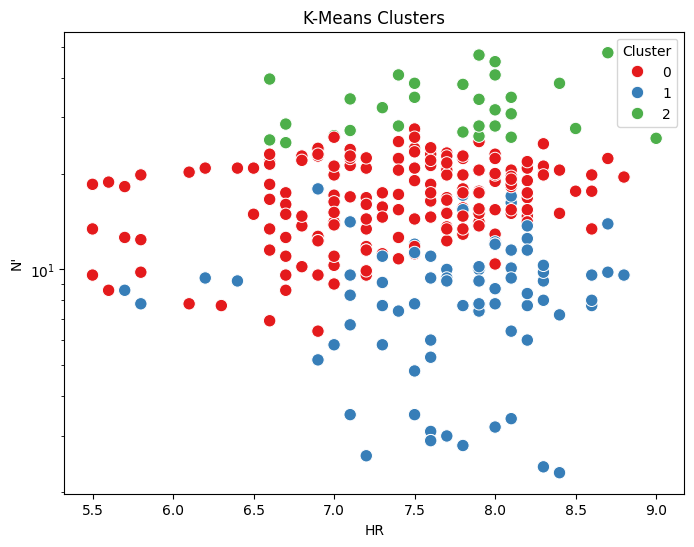

In [77]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_cluster,
    x="HR",
    y="N'",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.yscale("log")
plt.title("K-Means Clusters")
plt.show()

In [78]:
cluster_summary = (
    df_cluster
    .groupby("Cluster")
    .mean()
)

cluster_summary

,Q',N',HR,ELOS (m)
Cluster,,,,
0,7.518889,17.162222,7.371667,0.308168
1,4.775000,8.771250,7.757500,1.358017
2,13.800000,32.976667,7.703333,0.543109


# Cluster Characteristics

The K-Means algorithm identified three distinct groups of stopes based on geotechnical and geometric parameters.

## Cluster 0 – Moderate Stability Group

This cluster contains stopes with moderate rock mass quality (Q' ≈ 7.5) and moderate stability numbers (N' ≈ 17.2). The average ELOS is relatively low (0.31 m), indicating generally acceptable stope performance and limited overbreak.

## Cluster 1 – Poor Stability Group

This cluster is characterized by the lowest Q' (≈ 4.8) and lowest N' (≈ 8.8) values. It also has the highest average ELOS (≈ 1.36 m), indicating greater overbreak and poorer stope stability. This group appears to represent the least favourable geotechnical conditions in the dataset.

## Cluster 2 – High Stability Group

This cluster exhibits the highest Q' (≈ 13.8) and N' (≈ 33.0) values, indicating the most favourable rock mass conditions. Despite having slightly larger hydraulic radii than Cluster 0, the average ELOS remains relatively low (0.54 m), suggesting generally stable stope behaviour.

# Discussion

The clustering analysis successfully identified three naturally occurring groups within the historical stope dataset.

The clusters appear to be primarily differentiated by rock mass quality and stability conditions rather than hydraulic radius, as HR values are similar across all groups. The strongest separation occurs in Q' and N' values.

Cluster 1 represents stopes with poorer rock mass conditions and substantially higher overbreak, while Clusters 0 and 2 represent progressively more favourable stability conditions. The results suggest that rock mass quality indicators have a stronger influence on grouping behaviour than stope size within this dataset.